# 5G network expansion: from subscribers to an investment decision

**Independent hypothetical case, prepared 21 November 2026.** All forecasts are illustrative nominal CAD. This is not a Bell engagement.

The question is whether a CAD $50M regional network build meets a 10% five-year investment hurdle. We first reproduce the simple teaching model, then add incremental revenue treatment, acquisition, maintenance capital, working capital and cash taxes. Every formula is explained in `documentation/methodology.md`; the readable Python implementation is `finance.py`.

## 1. Load the documented assumptions

The CSV is the reproducible baseline. Unsaved Excel changes are not inputs to this notebook. Real national observations live separately in `data/market_context.csv` and are used only as context, not forecasts.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'data/assumptions.csv').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'analysis'))
from finance import load_assumptions, evaluate, find_threshold
from run_analysis import validate_excel, monte_carlo

pd.options.display.float_format = '{:,.2f}'.format
assumptions = pd.read_csv(ROOT / 'data/assumptions.csv')
a = load_assumptions()
display(assumptions[['label', 'value', 'unit', 'classification']])

,label,value,unit,classification
0,Initial network CAPEX,"50,000,000.00",CAD,Illustrative
1,Investment horizon,5.00,years,Illustrative
2,Year 1 average active subscribers,"25,000.00",subscribers,Illustrative
3,Monthly ARPU,65.00,CAD/subscriber/month,Illustrative
4,Base net subscriber growth,0.15,annual rate,Illustrative
5,Year 1 network operating costs,"8,000,000.00",CAD/year,Illustrative
6,Network operating cost growth,0.03,annual rate,Illustrative
7,Discount rate,0.10,annual rate,Illustrative
8,Bear net subscriber growth,0.05,annual rate,Illustrative
9,Bull net subscriber growth,0.25,annual rate,Illustrative


## 2. Forecast subscribers, revenue and cash

Average subscribers generate revenue throughout a year. Linear within-year net growth makes the Year 1 opening base `25,000 / (1 + 15% / 2)`. The company pays acquisition costs for that opening base at Year 0. Later gross additions include net growth plus replacement cancellations. Net growth already includes churn, so we do not subtract it again.

Gross revenue is `average subscribers × monthly ARPU × 12`. The expanded case counts only 85% as incremental. FCF subtracts operating cash costs, taxes, maintenance CAPEX and changes in working capital. Depreciation is not a cash expense.

,year,opening_customers,average_customers,closing_customers,gross_additions,revenue,network_opex,acquisition_cost,cash_tax,capex,delta_nwc,fcf
0,0,0.00,0.00,"23,255.81","23,255.81",0.00,0.00,"3,488,372.09",0.00,"50,000,000.00",0.00,"-53,488,372.09"
1,1,"23,255.81","25,000.00","26,744.19","6,488.37","16,575,000.00","8,000,000.00","973,255.81",0.00,"1,000,000.00","331,500.00","6,270,244.19"
2,2,"26,744.19","28,750.00","30,755.81","7,461.63","19,061,250.00","8,240,000.00","1,119,244.19","1,003,152.03","1,030,000.00","49,725.00","7,619,128.78"
3,3,"30,755.81","33,062.50","35,369.19","8,580.87","21,920,437.50","8,487,200.00","1,287,130.81","1,874,638.81","1,060,900.00","57,183.75","9,153,384.13"
4,4,"35,369.19","38,021.87","40,674.56","9,868.00","25,208,503.12","8,741,816.00","1,480,200.44","2,612,897.11","1,092,727.00","65,761.31","11,215,101.27"
5,5,"40,674.56","43,725.16","46,775.75","11,348.20","28,989,778.59","9,004,070.48","1,702,230.50","3,473,581.03","1,125,508.81","75,625.51","13,608,762.27"


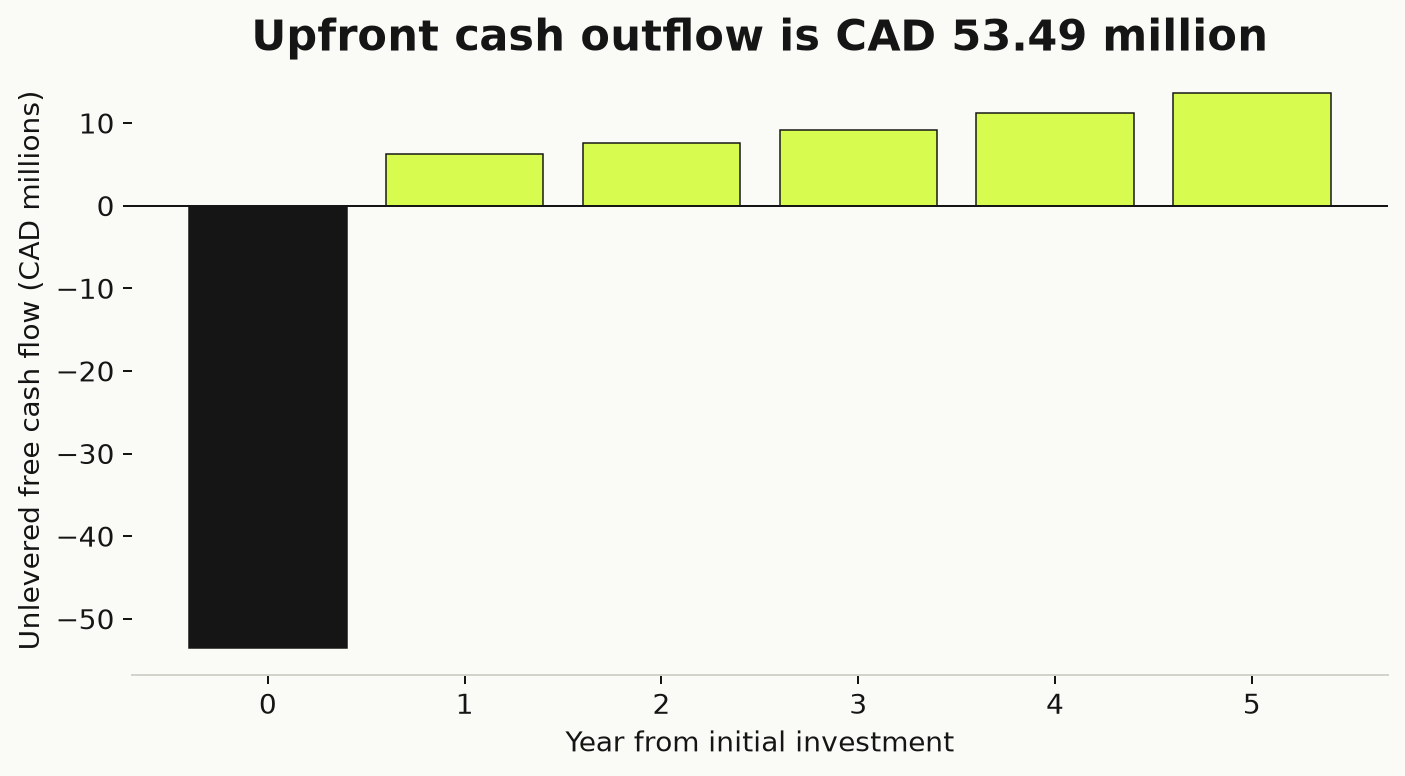

In [2]:
base = evaluate(a)
forecast = base['forecast']
display(forecast[['year', 'opening_customers', 'average_customers',
                  'closing_customers', 'gross_additions', 'revenue',
                  'network_opex', 'acquisition_cost', 'cash_tax',
                  'capex', 'delta_nwc', 'fcf']])
display(Image(filename=str(ROOT / 'outputs/charts/annual_cash_flow.png'), width=850))

## 3. Distinguish the simplified model from the expanded case

NPV discounts the future cash flows, then adds the immediate Year 0 outflow exactly once. Cash ROI uses cumulative net cash divided by initial cash spending. IRR is an annual rate. Neither payback measure is invented if the initial cash remains unrecovered at Year 5.

The simplified model deliberately excludes important economic costs. Comparing its result with the expanded case demonstrates why model scope changes the decision.

,Simplified,Expanded
initial_outflow,"50,000,000.00","53,488,372.09"
npv,"15,048,079.83","-18,504,240.74"
irr,0.20,-0.03
roi,0.78,-0.11
payback,3.34,NaN
discounted_payback,4.03,NaN
tco,"92,473,086.48","107,832,656.13"
cumulative_revenue,"131,476,434.37","111,754,969.22"


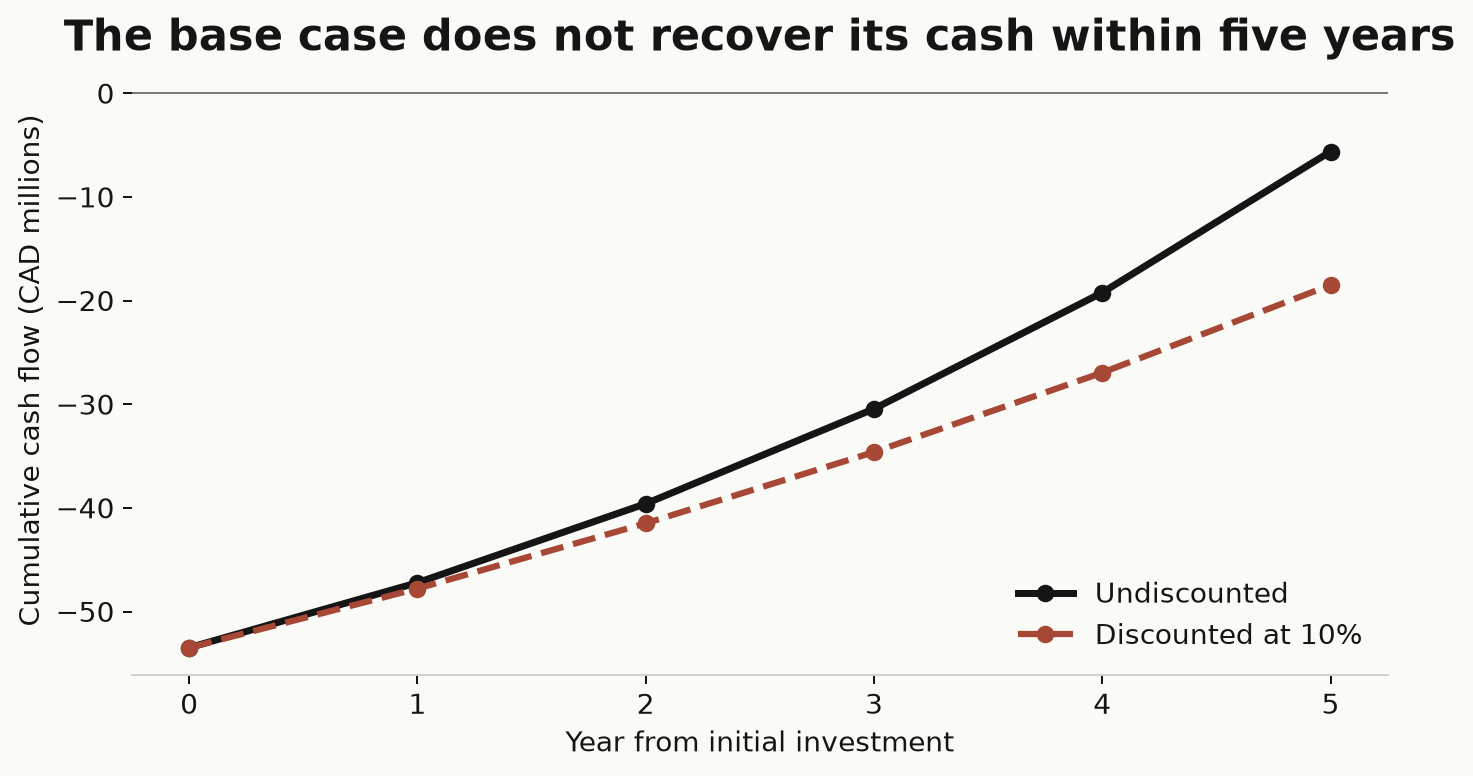

In [3]:
simple = evaluate(a, expanded=False)
metrics = pd.DataFrame({'Simplified': simple['metrics'], 'Expanded': base['metrics']})
display(metrics.loc[['initial_outflow', 'npv', 'irr', 'roi', 'payback',
                     'discounted_payback', 'tco', 'cumulative_revenue']])
display(Image(filename=str(ROOT / 'outputs/charts/cumulative_cash_flow.png'), width=850))

## 4. Compare adoption scenarios and the capacity constraint

Only net growth changes. The Year 1 average stays at 25,000, so higher growth implies a slightly smaller opening subscriber base. The 60,000-line ceiling is illustrative, not an engineering study. A scenario that exceeds it needs additional scope and costs before its returns can support a real decision.

,npv,irr,roi,payback,year5_closing_customers,year5_capacity_utilization
Bear,"-26,895,251.29",-0.12,-0.34,NaN,"31,128.82",0.52
Base,"-18,504,240.74",-0.03,-0.11,NaN,"46,775.75",0.78
Bull,"-8,646,550.96",0.05,0.17,4.56,"67,816.84",1.13


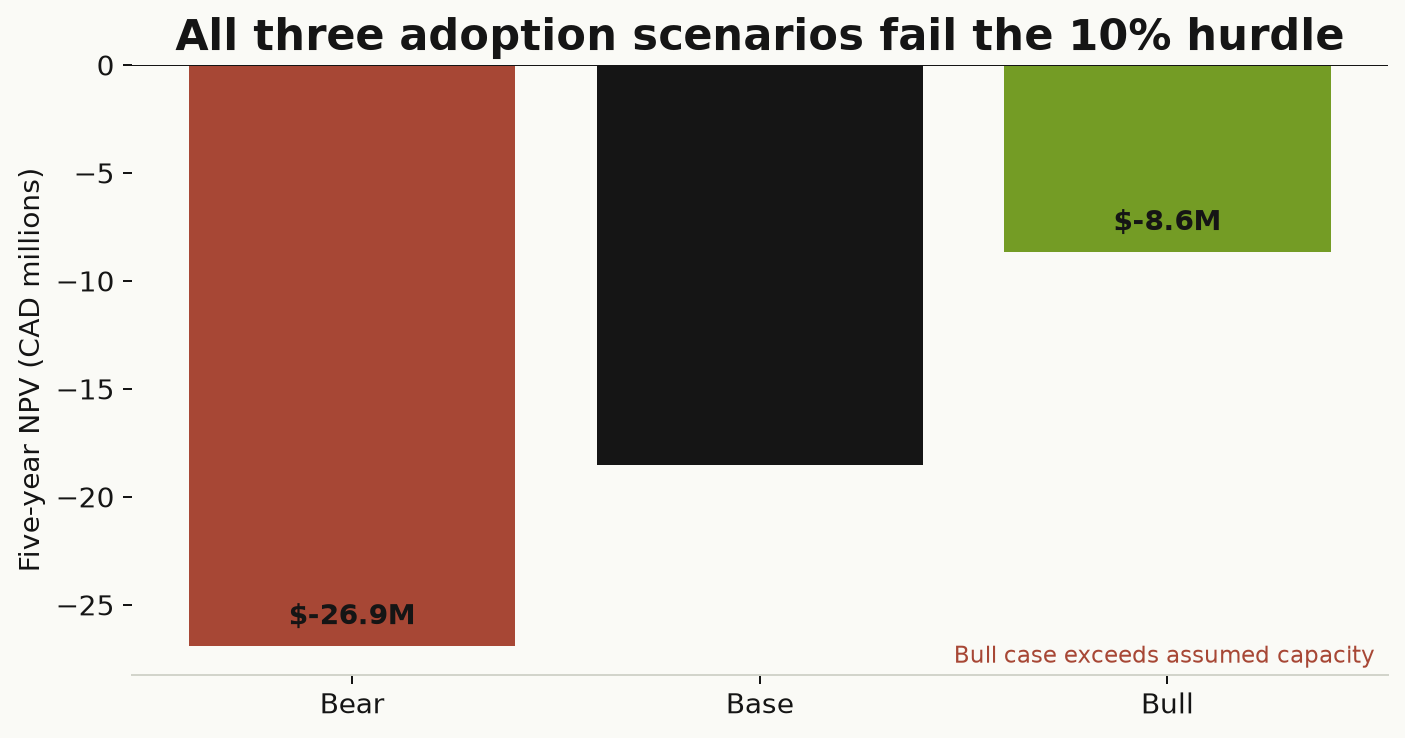

In [4]:
scenarios = {}
for name, key in [('Bear', 'bear_growth'), ('Base', 'base_growth'), ('Bull', 'bull_growth')]:
    scenarios[name] = evaluate(a, a[key])['metrics']
comparison = pd.DataFrame(scenarios).T
display(comparison[['npv', 'irr', 'roi', 'payback',
                    'year5_closing_customers', 'year5_capacity_utilization']])
display(Image(filename=str(ROOT / 'outputs/charts/scenario_comparison.png'), width=850))

## 5. Find break-even conditions instead of guessing a recommendation

Bisection searches for a zero-NPV threshold only if the specified interval contains a root. All other assumptions stay fixed. A mathematical demand threshold can still be operationally infeasible. Price and growth interact, which is why a two-input sensitivity matrix adds information beyond a single optimistic case.

Monthly ARPU (CAD)                        85.11
Year 1 average customers              33,623.87
Initial network CAPEX (CAD)       31,019,938.41
Incremental share in [10%,100%]             NaN
Name: Zero-NPV threshold, dtype: float64

Closing subscribers at demand break-even: 62911
Assumed capacity: 60000


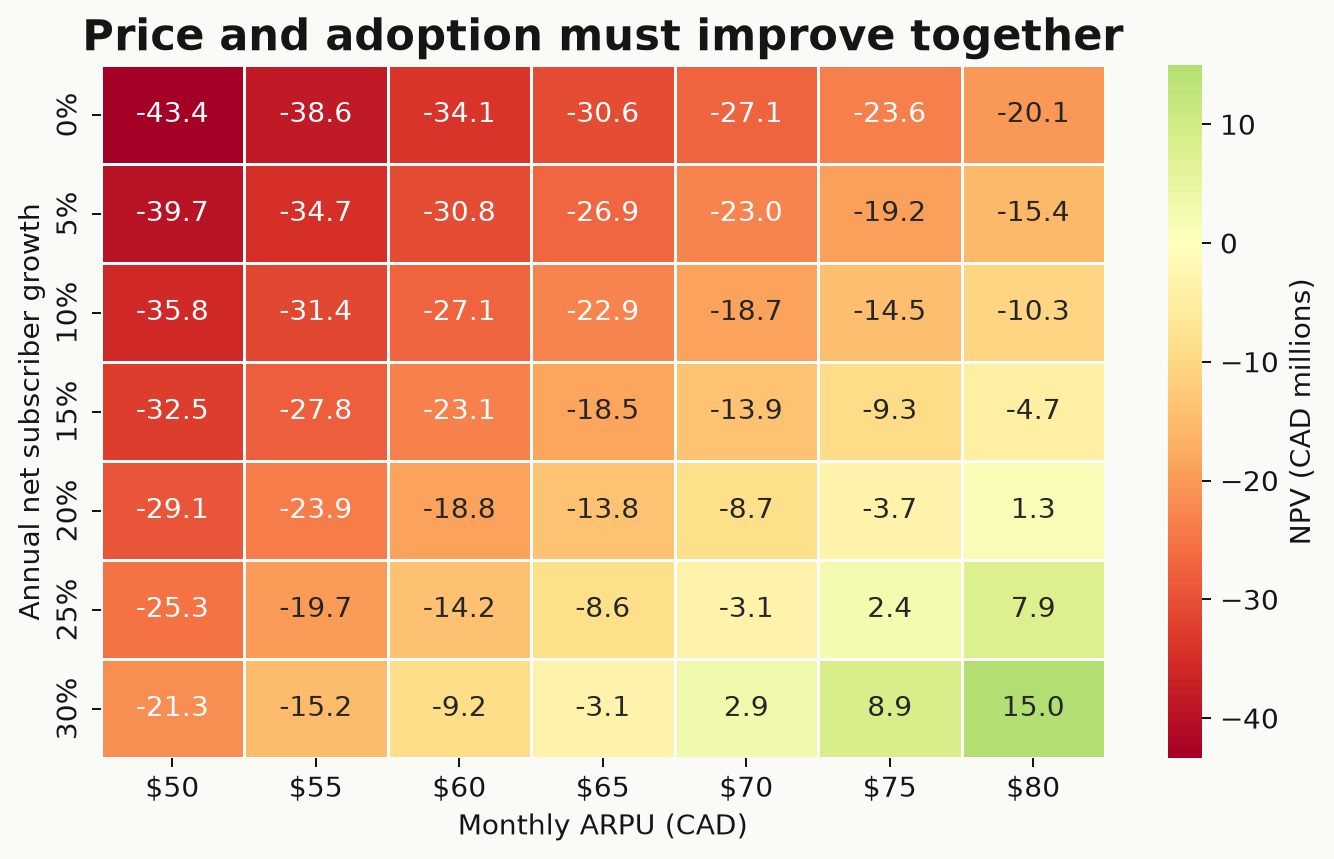

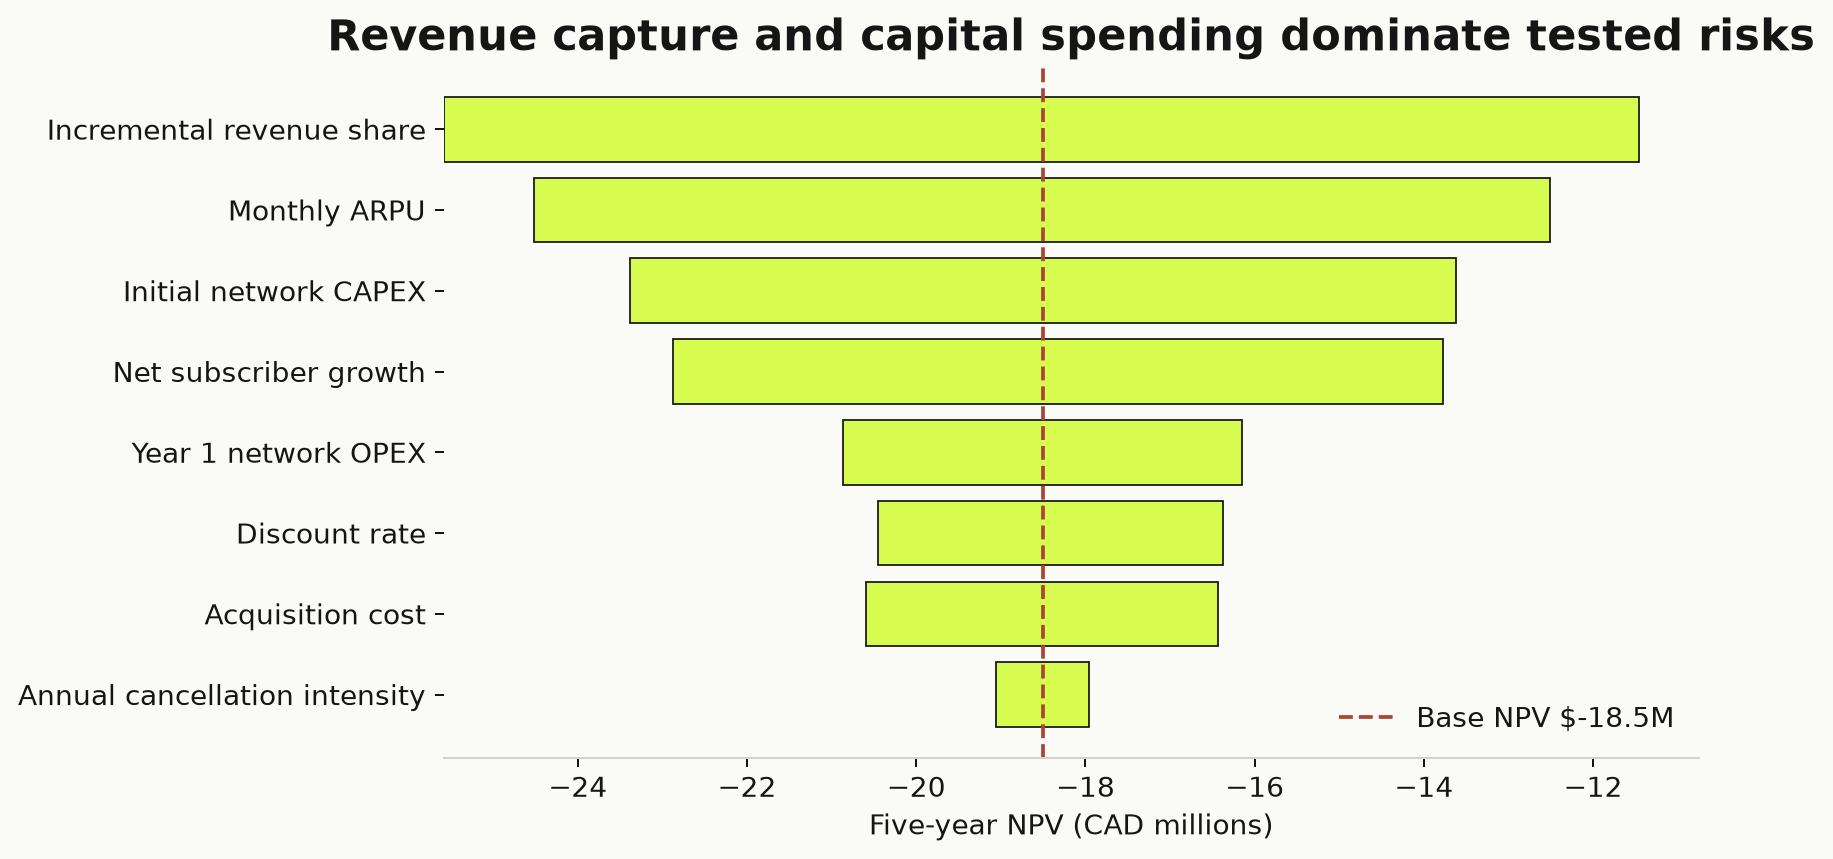

In [5]:
thresholds = {
    'Monthly ARPU (CAD)': find_threshold(a, 'arpu', 20, 150),
    'Year 1 average customers': find_threshold(a, 'year1_customers', 1000, 100000),
    'Initial network CAPEX (CAD)': find_threshold(a, 'initial_capex', 1e6, 100e6),
    'Incremental share in [10%,100%]': find_threshold(a, 'incremental_share', .1, 1),
}
display(pd.Series(thresholds, name='Zero-NPV threshold'))
threshold_demand = evaluate(dict(a, year1_customers=thresholds['Year 1 average customers']))
print('Closing subscribers at demand break-even:', round(threshold_demand['metrics']['year5_closing_customers']))
print('Assumed capacity:', int(a['subscriber_capacity']))
display(Image(filename=str(ROOT / 'outputs/charts/npv_sensitivity.png'), width=850))
display(Image(filename=str(ROOT / 'outputs/charts/tornado.png'), width=850))

## 6. Reconcile separate Excel and Python calculations

The workbook builder calculates Excel formulas using Artifact Tool and captures the same model at each scenario. Python independently recalculates subscriber flow, operating schedules and cash returns. This check compares those results; it does not ask Python to evaluate Excel formula text.

The capture belongs to the delivered baseline. If you change the CSV, reconciliation should fail until the workbook and its capture are rebuilt. This is not a fresh Microsoft Excel desktop test.

In [6]:
validation = validate_excel(a)
display(pd.Series(validation))
reconciliation = pd.read_csv(ROOT / 'outputs/excel_python_reconciliation.csv')
display(reconciliation.head(12))
assert validation['status'] == 'passed'

status                                                                    passed
principal_checks                                                             279
sensitivity_checks                                                            49
maximum_absolute_difference                                                 0.00
scope                          Artifact Tool calculated Excel formulas indepe...
dtype: object

,scenario,metric,excel,python,difference,tolerance
0,Bear,npv,"-26,895,251.29","-26,895,251.29",-0.00,0.01
1,Bear,irr,-0.12,-0.12,-0.00,0.00
2,Bear,roi,-0.34,-0.34,-0.00,0.00
3,Bear,initial_outflow,"53,658,536.59","53,658,536.59",0.00,0.01
4,Bear,tco,"104,938,079.14","104,938,079.14",0.00,0.01
5,Bear,cumulative_revenue,"91,587,337.97","91,587,337.97",0.00,0.01
6,Bear,cumulative_net_cash,"-18,054,225.82","-18,054,225.82",-0.00,0.01
7,Bear,payback,NaN,NaN,0.00,0.00
8,Bear,discounted_payback,NaN,NaN,0.00,0.00
9,Bear,average_customers_year_0,0.00,0.00,0.00,0.01


## 7. Optional uncertainty simulation

The simulation uses 5,000 independent triangular priors documented in the methodology. The positive-NPV share is conditional on those assumptions. It is not an empirically estimated probability that a telecom project will succeed. Forecasts above capacity omit the cost of extra capacity, so the simulation should not justify investment approval.

count         5,000.00
mean    -22,099,798.02
std       7,048,792.22
min     -44,965,151.04
5%      -33,339,158.81
50%     -22,304,796.37
95%     -10,109,159.98
max       3,621,895.31
Name: npv, dtype: float64

Conditional positive-NPV share: 0.1%


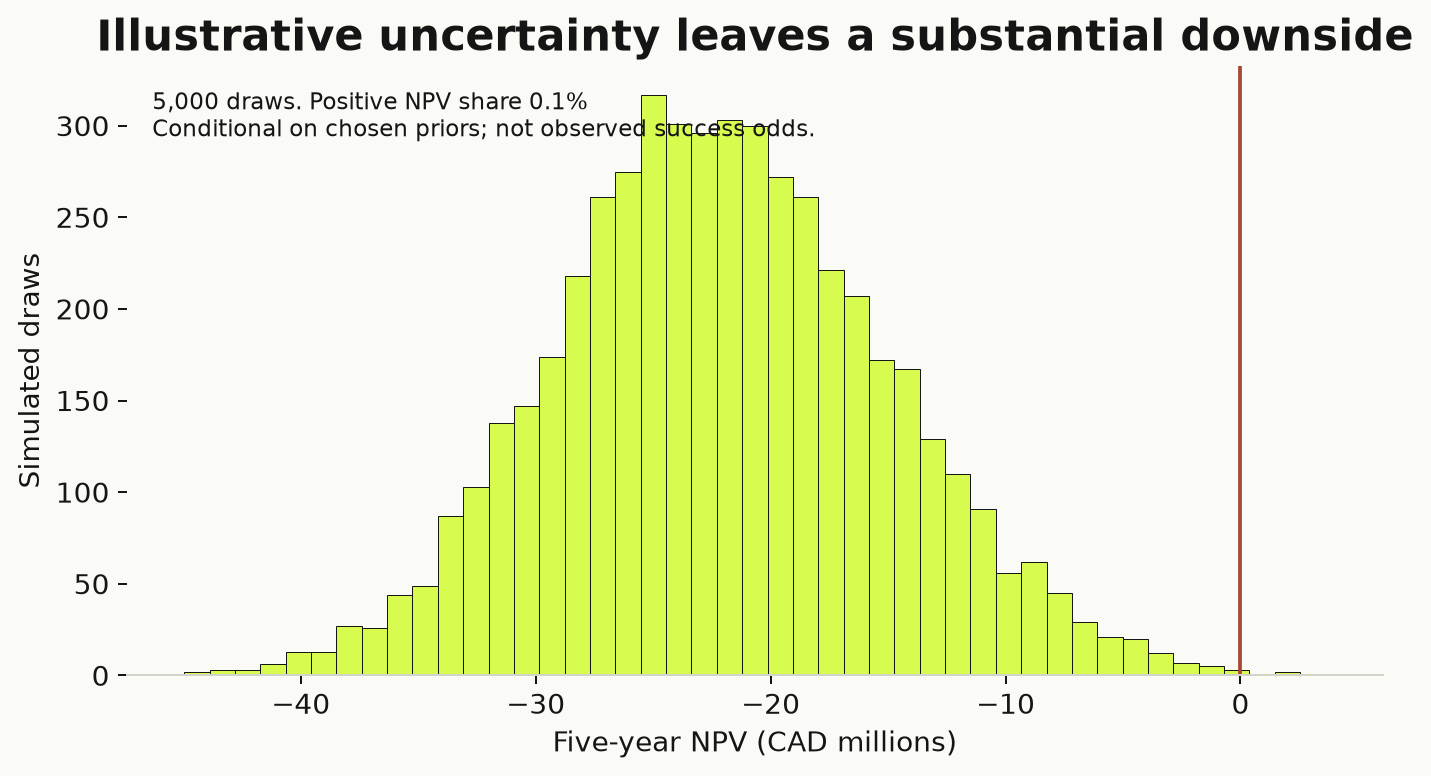

In [7]:
draws = monte_carlo(a, size=5000, seed=20261121)
display(draws['npv'].describe(percentiles=[.05, .5, .95]))
print(f"Conditional positive-NPV share: {(draws['npv'] > 0).mean():.1%}")
display(Image(filename=str(ROOT / 'outputs/charts/monte_carlo_npv.png'), width=850))

## 8. Investment recommendation

**Defer the full CAD $50M build and investigate a shared or smaller design.** The default expanded base case fails the five-year hurdle, and even high adoption requires added capacity without reaching positive NPV. Cost reduction is not assured; supplier quotes and engineering scope must support it.

The five-year cutoff omits later operating value from a network assumed to last longer. A supported lifecycle appraisal could change the decision. Neither book value nor an invented subsidy should be used as a cash plug.

Before an investment committee approval, validate local price-tested demand, achievable opening adoption, customer migration economics, quoted CAPEX/OPEX, spectrum and site access, and engineered capacity. The roadmap and KPI framework turn those conditions into proposed decision gates.

Sources: [CRTC 2026 CTMR](https://crtc.gc.ca/eng/publications/reports/PolicyMonitoring/2026/ctmr.htm), [BCE 2025 Annual Financial Report](https://www.bce.ca/cs-assets/2025-bce-annual-financial-report.pdf-blt5d552f866d8a58a3), and `data/sources.md`.